# CSE475 Task 2 (part 1): baselines on Bonn EEG
**Group 02** — Md. Anwar Nabil Araf (2023-2-60-242), Jagannath Banik (2023-2-60-144), Md Naimul Islam Rafi (2023-2-60-209), Mst Mahabuba Akter Eka (2023-1-60-134). Submitted to Associate Professor Dr. Raihan ul Islam.

**What this notebook does.** Trains the standard models we must beat, on the *same* fixed split from Task 1 (`outputs/task1/split_manifest.csv`): 300 train / 100 validation / 100 test segments, 20 per class in validation and test.

**Split honesty.** Bonn releases no patient or recording IDs, so this split is by segment, not by subject. We cannot rule out that segments from the same patient sit in both train and test. All results here are therefore *segment-level* and may be optimistic for unseen patients. The test set is used once per model; nothing is tuned on it.

In [1]:
from pathlib import Path
import sys, json, time
import numpy as np, pandas as pd
from IPython.display import display, Image, Markdown
# Works locally and in Colab: find the repo root, or clone it.
here = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'outputs/task1/split_manifest.csv').exists()), None)
if here is None:
    here = Path('Group02_Bonn_CSE475').resolve()
    if not here.exists():  # clone once; re-running the cell reuses the folder
        import subprocess; subprocess.run(['git', 'clone', '-q', 'https://github.com/nabilaraf41/Group02_Bonn_CSE475.git'], check=True)
ROOT = here
sys.path.insert(0, str(ROOT/'code/task2'))
import task2 as t2
OUT = ROOT/'outputs/task2'; OUT.mkdir(parents=True, exist_ok=True)
X, y, split, paths, fs, features = t2.load(ROOT)
print('Signals:', X.shape, '| fs =', fs, 'Hz')
print(pd.crosstab(pd.Series(split, name='split'), pd.Series(np.array(t2.CLASSES)[y], name='class')))

Signals: (500, 4097) | fs = 173.61 Hz
class        F   N   O   S   Z
split                         
test        20  20  20  20  20
train       60  60  60  60  60
validation  20  20  20  20  20


## Preprocessing
- **Features:** the 19 Task 1 descriptors (13 time-domain, 6 spectral) computed per segment. No missing values, so no imputation.
- **Scaling:** `StandardScaler` inside each pipeline, so it is fitted on the training rows only (trees need no scaling).
- **Balance:** 60/20/20 per class in train/val/test, so no resampling. We still report macro-F1 and per-class recall.
- **Feature selection:** none here. Task 1 found 7 highly correlated pairs (e.g. RMS vs std, r = 0.996); removing them is an ablation for Task 3.
- **1D-CNN** sees the raw 4,097-sample signal, divided by one amplitude scale computed from training segments only.

In [2]:
F = t2.segment_features(X, fs, features)
F.assign(path=paths, label=np.array(t2.CLASSES)[y], split=split).to_csv(OUT/'segment_features.csv', index=False)
classical, probas = t2.run_classical(F.to_numpy(), y, split)
cnn_row, probas['1D-CNN (raw signal)'] = t2.train_cnn1d(X, y, split)
baselines = pd.concat([classical, pd.DataFrame([cnn_row])], ignore_index=True).sort_values('f1_macro', ascending=False)
baselines.to_csv(OUT/'baseline_results.csv', index=False)
np.savez(OUT/'baseline_test_probas.npz', **{k.replace(' ', '_'): v for k, v in probas.items()})
display(baselines.round(4))

C:\Users\Admin\AppData\Local\Temp\claude\29e0d635496bc46f\523eefa9-c65a-409a-8cdb-8bd67dd878f4\scratchpad\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,model,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,roc_auc_ovr_macro,pr_auc_macro,recall_Z,recall_O,recall_N,recall_F,recall_S,train_time_s,inference_time_s,parameters
4,Random Forest,0.86,0.8610,0.86,0.8595,0.8610,0.86,0.8595,0.9760,0.9102,0.90,0.90,0.70,0.80,1.00,2.0983,0.1990,NaN
5,Gradient Boosting,0.85,0.8538,0.85,0.8514,0.8538,0.85,0.8514,0.9720,0.9090,0.90,0.90,0.75,0.75,0.95,2.4581,0.0045,NaN
6,XGBoost,0.82,0.8194,0.82,0.8174,0.8194,0.82,0.8174,0.9702,0.8930,0.90,0.90,0.55,0.75,1.00,2.6343,0.0121,NaN
1,SVM (RBF),0.82,0.8258,0.82,0.8090,0.8258,0.82,0.8090,0.9639,0.8753,0.95,0.90,0.85,0.45,0.95,0.0499,0.0067,NaN
0,Logistic Regression,0.81,0.8201,0.81,0.8057,0.8201,0.81,0.8057,0.9644,0.8726,0.90,0.85,0.85,0.50,0.95,0.0669,0.0016,NaN
8,1D-CNN (raw signal),0.80,0.8112,0.80,0.7922,0.8112,0.80,0.7922,0.9688,0.8824,0.90,0.90,0.80,0.40,1.00,66.5936,0.0383,13573.0
3,Decision Tree,0.78,0.7849,0.78,0.7767,0.7849,0.78,0.7767,0.8625,0.6725,0.80,0.95,0.50,0.70,0.95,0.0089,0.0006,NaN
2,k-NN (k=5),0.76,0.7778,0.76,0.7563,0.7778,0.76,0.7563,0.9479,0.7966,0.90,0.80,0.70,0.45,0.95,0.0054,0.1207,NaN
7,MLP,0.69,0.7086,0.69,0.6870,0.7086,0.69,0.6870,0.9175,0.7265,0.95,0.55,0.60,0.40,0.95,0.1490,0.0014,NaN


Baseline to beat: Random Forest
              precision    recall  f1-score   support

           Z      0.818     0.900     0.857        20
           O      0.947     0.900     0.923        20
           N      0.778     0.700     0.737        20
           F      0.762     0.800     0.780        20
           S      1.000     1.000     1.000        20

    accuracy                          0.860       100
   macro avg      0.861     0.860     0.860       100
weighted avg      0.861     0.860     0.860       100



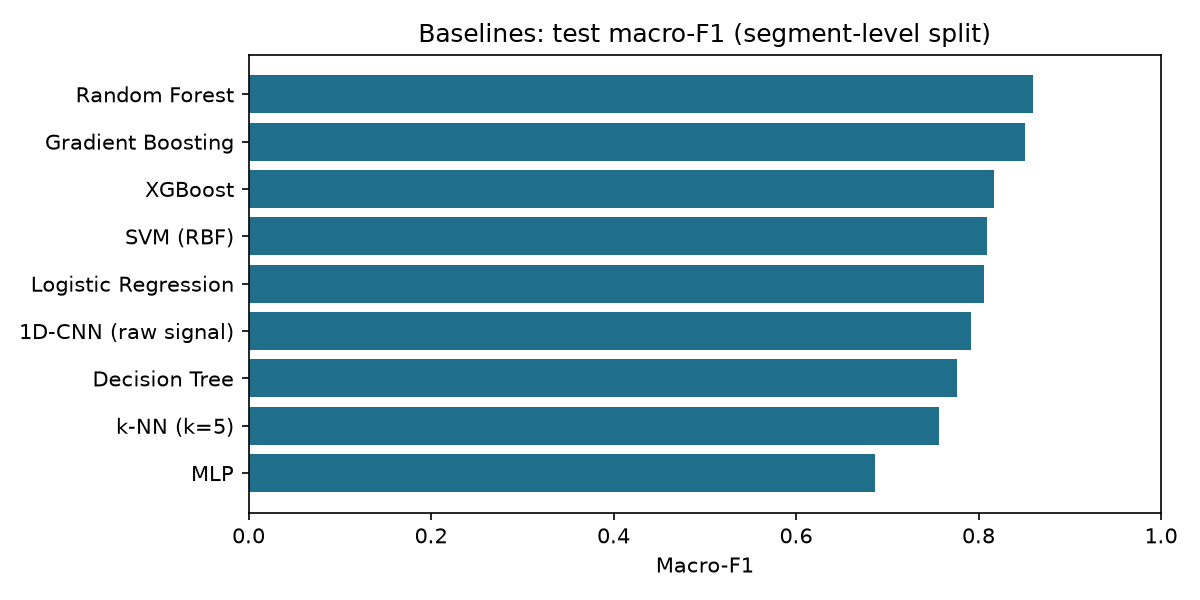

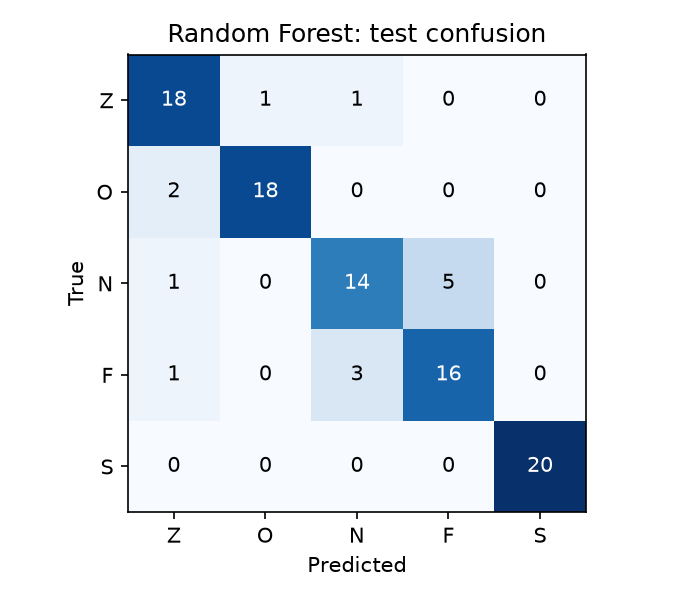

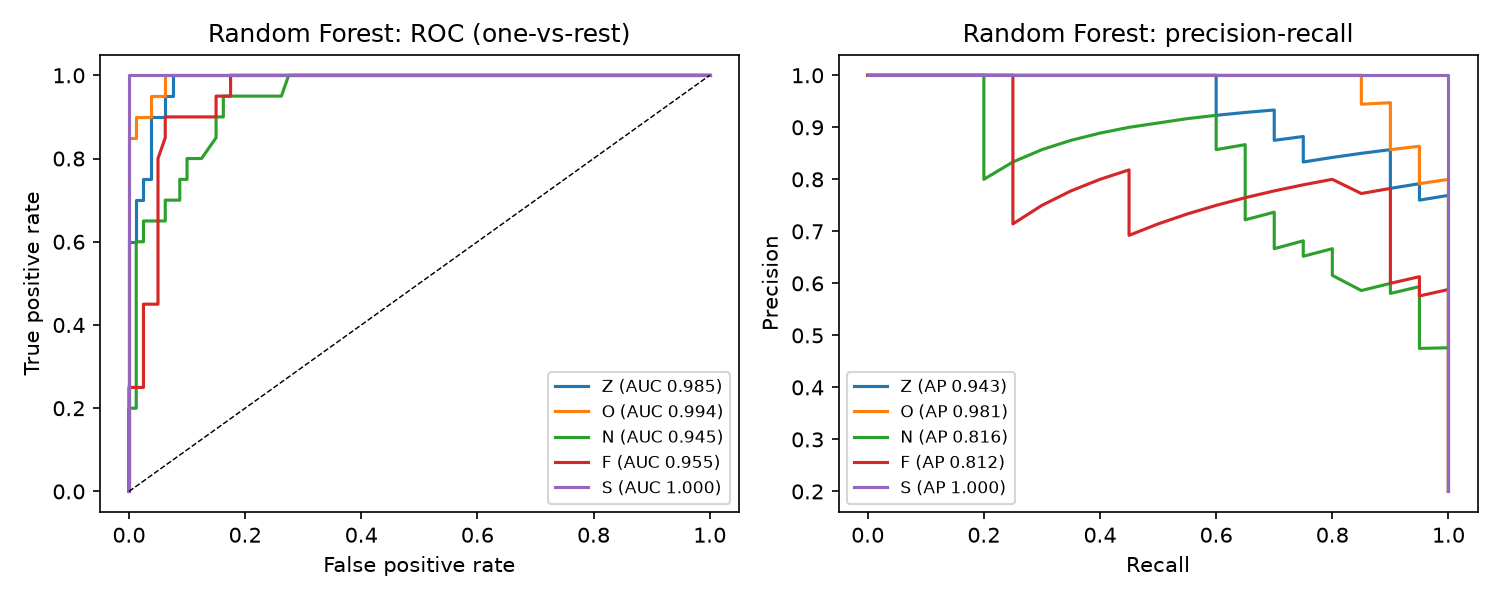

In [3]:
best = baselines.iloc[0]['model']
yt = y[split == 'test']; pb = probas[best]
print('Baseline to beat:', best)
print(t2.classification_report(yt, pb.argmax(1), target_names=t2.CLASSES, digits=3))
t2.plot_confusion(yt, pb.argmax(1), f'{best}: test confusion', OUT/'baseline_best_confusion.png')
t2.plot_roc_pr(yt, pb, best, OUT/'baseline_best_roc_pr.png')
fig, ax = t2.plt.subplots(figsize=(8, 4))
b = baselines.set_index('model')
ax.barh(b.index, b.f1_macro, color='#1f6f8b'); ax.invert_yaxis()
ax.set(title='Baselines: test macro-F1 (segment-level split)', xlabel='Macro-F1', xlim=(0, 1))
fig.tight_layout(); fig.savefig(OUT/'baseline_macro_f1.png', dpi=150)
for f in ['baseline_macro_f1.png', 'baseline_best_confusion.png', 'baseline_best_roc_pr.png']: display(Image(filename=str(OUT/f)))

## Reading the baseline results
- **Baseline to beat: Random Forest**, test macro-F1 **0.860** (accuracy 0.86). Gradient Boosting is close (0.851). With 100 test segments, one segment = 1 percentage point, so the top three tree models are within about 4 segments of each other.
- **Seizure (S) is easy**: recall 0.95–1.00 for every model. High amplitude and line length (Task 1) separate it.
- **The hard pair is N vs F** (both interictal, intracranial). Linear models and SVM recall only 0.45–0.50 of F; Random Forest gets 0.80 F and 0.70 N. This matches the Task 1 overlap in spectral entropy (F/N medians 0.551 / 0.550).
- **1D-CNN on raw signal (0.792)** is not better than features + trees, at 30× the training time. With only 300 training segments a CNN has little data to learn its own features.
- **MLP is weakest (0.687)**: early stopping keeps only 10% of 300 rows for validation, so it stops very early.
- Tree models are single runs with seed 475; their run-to-run spread is not measured here (Task 3 adds 5-fold CV).